# Detection and alignment

Two stages need to know where the face is. **Anonymization** needs the region to blur, pixelate or cover. **Recognition** needs the face warped onto the 112x112 frame its models were trained on, because a recognition model compares faces only if they are presented the same way.

The detector is [YuNet](https://github.com/opencv/opencv_zoo/tree/main/models/face_detection_yunet), a 227 KiB model run through OpenCV. It returns a bounding box, a score, and five landmarks - both eyes, the nose tip and the two mouth corners - which are what the alignment needs.

## Why it has no threshold

A face detector normally needs a score threshold to answer "is there a face here?". A frame of this corpus is one image of a VoxCeleb2 face track, so it shows exactly one subject by construction and that question is already answered. The detector is asked for its single highest-scoring candidate with the score threshold set to zero, which leaves no parameter to choose and no frame without a detection.

This notebook shows what that decision costs and what it buys.

In [1]:
import cv2
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from tqdm.auto import tqdm

from meles.alignment import align_face
from meles.detection import default_detector
from meles.paths import repository_root

sns.set_theme(style="whitegrid")

ROOT = repository_root()
DATA = ROOT / "data"
SAMPLE = 2000
SEED = 0

# The score OpenCV's detector defaults to, shown here as the alternative to no threshold at all.
OPENCV_DEFAULT_SCORE = 0.9

structure = pd.read_parquet(DATA / "voxceleb2.parquet", columns=["identity", "video", "path"])
sample = structure.sample(SAMPLE, random_state=SEED)

rows = []
for path in tqdm(sample["path"], desc="frames"):
    image = cv2.imread(str(DATA / path))
    height, width = image.shape[:2]
    area = default_detector.detect(image)
    rows.append(
        {
            "found": area is not None,
            "confidence": area.confidence if area else np.nan,
            # How much of the frame the detected face covers.
            "box_fraction": (area.w * area.h) / (width * height) if area else np.nan,
            "path": path,
        }
    )

detections = pd.DataFrame(rows)
print(f"frames with a detection: {detections['found'].mean():.2%} of {len(detections):,}")
print(
    f"below the OpenCV default score of {OPENCV_DEFAULT_SCORE}: "
    f"{(detections['confidence'] < OPENCV_DEFAULT_SCORE).mean():.2%}"
)
detections[["confidence", "box_fraction"]].describe()


frames:   0%|          | 0/2000 [00:00<?, ?it/s]

frames with a detection: 100.00% of 2,000
below the OpenCV default score of 0.9: 1.95%


,confidence,box_fraction
count,2000.000000,2000.000000
mean,0.937898,0.386591
std,0.013262,0.046233
min,0.791431,0.016442
25%,0.933176,0.358080
50%,0.941131,0.381836
75%,0.946239,0.411352
max,0.959205,0.675781


In [2]:
detections_least_box_fraction = detections.sort_values(by='box_fraction')
detections_least_box_fraction.head()

,found,confidence,box_fraction,path
829,True,0.900678,0.016442,voxceleb2/id08725/jj-DvdxSFpA/00110.0005.jpg
1263,True,0.894924,0.249920,voxceleb2/id09210/enwm8winkEw/00409.0000.jpg
344,True,0.931017,0.251415,voxceleb2/id09008/f2JXJSXiMp4/00110.0007.jpg
851,True,0.889395,0.256657,voxceleb2/id08603/yZtNvpqNqxM/00378.0000.jpg
1639,True,0.891514,0.258351,voxceleb2/id01893/nKoptdnft30/00261.0013.jpg


The score distribution is what decides whether a threshold would be doing anything. A threshold only matters where it cuts; everything to the right of it is kept either way.

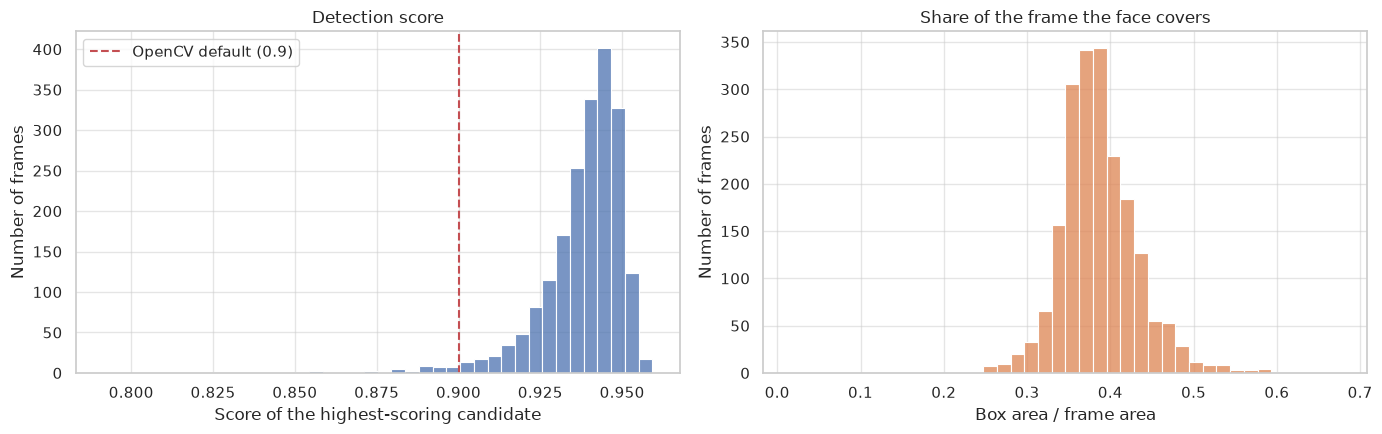

In [3]:
fig, (ax_1, ax_2) = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(detections["confidence"], bins=40, color="#4C72B0", ax=ax_1)
ax_1.axvline(OPENCV_DEFAULT_SCORE, color="#C44E52", linestyle="--", label=f"OpenCV default ({OPENCV_DEFAULT_SCORE})")
ax_1.set_title("Detection score")
ax_1.set_xlabel("Score of the highest-scoring candidate")
ax_1.set_ylabel("Number of frames")
ax_1.legend()

sns.histplot(detections["box_fraction"], bins=40, color="#DD8452", ax=ax_2)
ax_2.set_title("Share of the frame the face covers")
ax_2.set_xlabel("Box area / frame area")
ax_2.set_ylabel("Number of frames")

fig.tight_layout()
plt.show()

Taking the *highest-scoring* candidate is only a choice where there is more than one candidate. Running the same detector at OpenCV's default score - the setting that decides which candidates count as faces at all - shows how often that happens, and whether picking the largest box instead would have landed anywhere else.


In [4]:
from meles.detection import YUNET
from meles.weights import resolve

thresholded = cv2.FaceDetectorYN.create(str(resolve(YUNET)), "", (0, 0), OPENCV_DEFAULT_SCORE, 0.3, 5000)

counts, disagreements = [], 0
for path in tqdm(sample["path"], desc="frames"):
    image = cv2.imread(str(DATA / path))
    thresholded.setInputSize((image.shape[1], image.shape[0]))
    found, candidates = thresholded.detect(image)
    candidates = candidates if (found and candidates is not None) else np.empty((0, 15), np.float32)
    counts.append(len(candidates))

    if len(candidates) > 1:
        by_score = candidates[candidates[:, -1].argmax()]
        by_area = candidates[(candidates[:, 2] * candidates[:, 3]).argmax()]
        disagreements += int(not np.allclose(by_score[:4], by_area[:4]))

counts = pd.Series(counts)
print(f"frames with no candidate:        {(counts == 0).sum():5,}  ({(counts == 0).mean():.2%})")
print(f"frames with exactly one:         {(counts == 1).sum():5,}  ({(counts == 1).mean():.2%})")
print(f"frames with more than one:       {(counts > 1).sum():5,}  ({(counts > 1).mean():.2%})")
print(f"of those, largest box differs:   {disagreements:5,}")


frames:   0%|          | 0/2000 [00:00<?, ?it/s]

frames with no candidate:           39  (1.95%)
frames with exactly one:         1,959  (97.95%)
frames with more than one:           2  (0.10%)
of those, largest box differs:       0


## Alignment

The five landmarks are fitted onto a fixed reference - the ArcFace template, the same five points every model in this family was trained against - by a least-squares similarity transform, which may rotate, scale and translate the face but not distort it. The result is a 112x112 crop in which the eyes, nose and mouth sit in the same place for every frame, so that a difference between two crops is a difference between two faces rather than between two camera angles.

The frames below are drawn at random. The top row shows the detected box and landmarks, the bottom row the crop that the recognition models actually see.

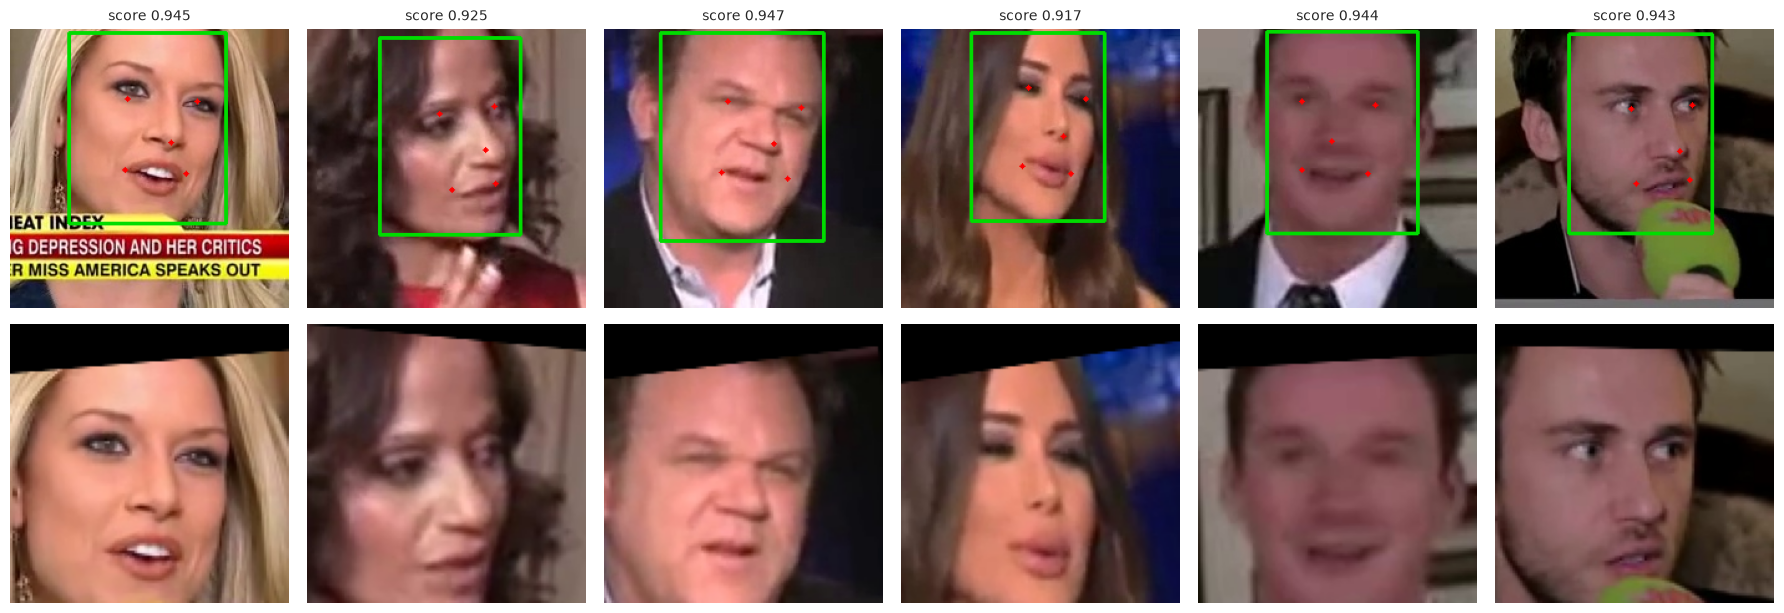

In [5]:
EXAMPLES = 6

fig, axes = plt.subplots(2, EXAMPLES, figsize=(3 * EXAMPLES, 6.4))
for column, path in enumerate(sample["path"].head(EXAMPLES)):
    image = cv2.imread(str(DATA / path))
    area = default_detector.detect(image)

    marked = image.copy()
    cv2.rectangle(marked, (area.x, area.y), (area.x + area.w, area.y + area.h), (0, 220, 0), 2)
    for x, y in area.landmarks:
        cv2.circle(marked, (int(round(x)), int(round(y))), 2, (0, 0, 255), -1)

    for row, picture in enumerate((marked, align_face(image, area.landmarks))):
        axes[row, column].imshow(cv2.cvtColor(picture, cv2.COLOR_BGR2RGB))
        axes[row, column].set_axis_off()
    axes[0, column].set_title(f"score {area.confidence:.3f}", fontsize=10)

axes[0, 0].set_ylabel("frame")
axes[1, 0].set_ylabel("aligned")
fig.tight_layout()
plt.show()

## The smallest boxes

The left tail of the box-fraction histogram is where a detection is most likely to be wrong: a face that covers almost none of the frame is also what the detector would return if it had latched onto something that is not the subject. These are the frames with the smallest boxes in the sample - one per identity, so a single bad track cannot fill the row - shown the same way as above.

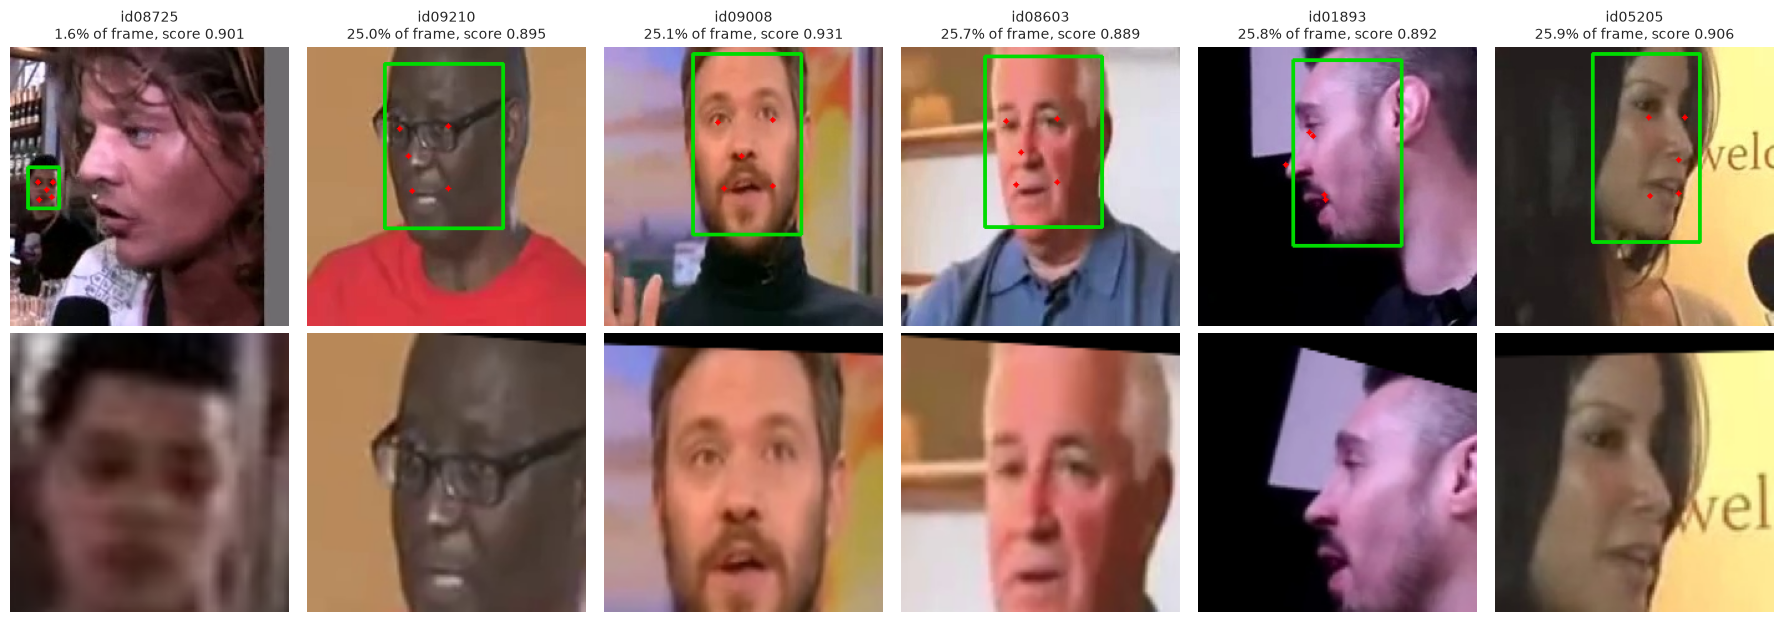

In [6]:
SMALLEST = 6

labelled = detections.merge(structure[["identity", "path"]], on="path", how="left")
smallest = labelled.sort_values("box_fraction").drop_duplicates("identity").head(SMALLEST)

fig, axes = plt.subplots(2, SMALLEST, figsize=(3 * SMALLEST, 6.4))
for column, row_ in enumerate(smallest.itertuples()):
    image = cv2.imread(str(DATA / row_.path))
    area = default_detector.detect(image)

    marked = image.copy()
    cv2.rectangle(marked, (area.x, area.y), (area.x + area.w, area.y + area.h), (0, 220, 0), 2)
    for x, y in area.landmarks:
        cv2.circle(marked, (int(round(x)), int(round(y))), 2, (0, 0, 255), -1)

    for row, picture in enumerate((marked, align_face(image, area.landmarks))):
        axes[row, column].imshow(cv2.cvtColor(picture, cv2.COLOR_BGR2RGB))
        axes[row, column].set_axis_off()
    title = f"{row_.identity}\n{row_.box_fraction:.1%} of frame, score {row_.confidence:.3f}"
    axes[0, column].set_title(title, fontsize=10)

fig.tight_layout()
plt.show()